# 05 · Frozen evaluation on a fresh quarter

Notebook 04 selected the improvements using 2025 only. This notebook loads its frozen pipelines and compares them with the original pipelines on the **same 10,000 April–June 2026 flights**. It does not train, tune, select new features or readjust thresholds.

January–March 2026 remains the original benchmark. Comparing its score directly with a Q2 score would mix model changes with different flight conditions. The original pipelines are therefore scored on Q2 as well.

All four classifiers are compared with A (schedule) and B (added weather/history/traffic), plus simple baselines. F1 is the primary warning rule; F0.5 appears only as an alternative operating policy. Fresh test scores are for confirmation and interpretation, not another round of model selection.

In [1]:
from pathlib import Path
import site
if site.ENABLE_USER_SITE:site.addsitedir(site.getusersitepackages())
import sys,json,hashlib
from datetime import datetime,timezone
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.svm import SVC
from sklearn.metrics import average_precision_score,confusion_matrix

ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks':ROOT=ROOT.parent
if (ROOT/'departure-delay-classification/config/project.json').exists():ROOT/='departure-delay-classification'
sys.path.insert(0,str(ROOT/'scripts'))
from baseline_integrity import verify_baseline_files
from fresh_test_data import build_q2_test
from improvement_exports import make_tables
REPORT=ROOT/'reports/improvements'
CONFIG=json.loads((ROOT/'config/project.json').read_text())
PREP=json.loads((ROOT/'reports/preparation_manifest.json').read_text())['feature_engineering']
selection=json.loads((REPORT/'selection.json').read_text())
quality=json.loads((REPORT/'weather_quality.json').read_text())
original=joblib.load(ROOT/'models/flight_delay_models.joblib')
improved=joblib.load(ROOT/'models/improved_flight_delay_models.joblib')
NAMES={'logistic_regression':'Logistic Regression','knn':'KNN','svm':'RBF SVM','random_forest':'Random Forest'}
SELECTED=('improved',selection['selected_model_id'],selection['selected_feature_set'])
SEED=42;BOOTSTRAPS=300
RUN_ID=selection['run_id']
EXPORT=ROOT/'tableau/exports/improved';EXPORT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid',palette=['#247BA0','#E08D3C','#5C946E','#8465A0'])
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
def table(x,**kw):print(x.to_string(**kw))
def plot():plt.tight_layout();plt.show()
def sha(path):
    with path.open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
def save_json(path,x):path.write_text(json.dumps(x,indent=2,allow_nan=False)+'\n')
assert sha(REPORT/'selection.json')==improved['selection_sha256']
assert sha(ROOT/'scripts/improvement_features.py')==selection['helper_sha256']
protected=json.loads((REPORT/'baseline_fingerprints.json').read_text())
baseline_integrity=verify_baseline_files(ROOT,protected)
raw_checks=json.loads((REPORT/'raw_source_checksums.json').read_text())
assert all(sha(ROOT/p)==v for p,v in raw_checks.items()),'A raw source changed after its integrity audit.'
inputs={str(p.relative_to(ROOT)):sha(p) for p in [ROOT/'models/improved_flight_delay_models.joblib',
 REPORT/'selection.json',REPORT/'weather_quality.json',REPORT/'raw_source_checksums.json',ROOT/'scripts/improvement_features.py',
 ROOT/'scripts/fresh_test_data.py',ROOT/'scripts/improvement_exports.py']}
for month in [4,5,6]:
    p=ROOT/f'data/raw/flights/bts/2026/csv/2026_{month:02d}.csv';inputs[str(p.relative_to(ROOT))]=sha(p)
protocol={'inputs':inputs,'test_rows':10000,'seed':SEED,'strata':['month','delayed_departure'],
 'test_period':['2026-04-01','2026-06-30'],'selected_before_test':list(SELECTED),
 'threshold_primary':'F1','secondary_policy':'F0.5, improved models only',
 'day_block_bootstrap_repetitions':BOOTSTRAPS,'bootstrap_seed':SEED,
 'bootstrap_scope':'paired AP differences for the four B models; conditional on fitted models',
 'no_refitting_or_retuning':True}
TEST_PROTOCOL_SHA=hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()
access_path=REPORT/'test_access.json'
if access_path.exists():
    access=json.loads(access_path.read_text())
    assert access['test_protocol_sha256']==TEST_PROTOCOL_SHA,'The test is already exposed under another procedure. Do not change the procedure.'
else:
    access={'first_outcomes_load_started_at_utc':datetime.now(timezone.utc).isoformat(),
            'test_protocol_sha256':TEST_PROTOCOL_SHA,'protocol':protocol}
    assert pd.Timestamp(access['first_outcomes_load_started_at_utc'])>pd.Timestamp(selection['frozen_at_utc'])
    save_json(access_path,access)
print('Frozen model:',SELECTED)
print('First fresh-test outcome loading began:',access['first_outcomes_load_started_at_utc'])

Frozen model: ('improved', 'logistic_regression', 'B')
First fresh-test outcome loading began: 2026-10-18T21:20:19.400814+00:00


## Apply the existing population, cutoff and quality rules

Raw flight data are parsed using the same rules as notebook 01. Cancellations and unknown departure labels are excluded; eligible diverted flights stay. All three months keep their natural class proportions in the frozen sample.

History remains a 28-day window ending seven days before each query cutoff. Within Q2, later flights may use **earlier Q2 outcomes** under that same rule; the model itself is never refitted. This simulates regularly updated historical context, with the existing unverified outcome-delivery assumption.

Both versions at the two approved ORD conflict timestamps are excluded. The source audit found 95 of 260,336 schedules without fresh weather (about 0.04%). Such flights stay; weather is missing and the saved training-fitted preprocessing handles it. The weather limit is not loosened to obtain a better match. No intermediate test CSV or Parquet is created.

In [2]:
test,test_audit=build_q2_test(ROOT,quality['excluded_station_times'],SEED,10000)
test=test.sort_values('flight_id').reset_index(drop=True)
assert len(test)==10000 and test['flight_id'].is_unique
COHORT_SHA=hashlib.sha256('\n'.join(test['flight_id'].astype(str)).encode()).hexdigest()
print('Eligible population:',test_audit['eligible_population'])
print('Sample:',len(test),'| delayed:',int(test['delayed_departure'].sum()))
print('Unmatched weather in sample, retained:',test_audit['test_weather_unmatched'])
table(test.groupby('month',observed=True)['delayed_departure'].agg(n='size',delayed='sum'),index=True)

def score(pipeline,columns):
    if isinstance(pipeline.named_steps['classifier'],SVC):return pipeline.decision_function(test[columns])
    ix=list(pipeline.named_steps['classifier'].classes_).index(1)
    return pipeline.predict_proba(test[columns])[:,ix]

evaluations=[]
def evaluate_model(m):
    for version,bundle in [('original',original),('improved',improved)]:
        for fs in ['A','B']:
            item=bundle['models'][m+'__'+fs]
            columns=PREP['feature_sets'][fs] if version=='original' else item['columns']
            start=perf_counter();s=score(item['pipeline'],columns);seconds=perf_counter()-start
            assert np.isfinite(s).all()
            e={'version':version,'model_id':m,'feature_set':fs,'scores':s,'threshold':item['threshold'],
               'score_type':item['score_type'],'prediction_seconds':seconds,'fit_seconds':item.get('fit_seconds')}
            if version=='improved':e['threshold_f05']=item['thresholds']['F0.5']
            evaluations.append(e)
            print(f'Q2 scored: {version}/{m}/{fs} · {seconds:.2f}s',flush=True)
evaluate_model('logistic_regression')

Eligible population: 254333
Sample: 10000 | delayed: 2557
Unmatched weather in sample, retained: 4
          n  delayed
month               
4      3292      778
5      3425      845
6      3283      934
Q2 scored: original/logistic_regression/A · 0.01s


Q2 scored: original/logistic_regression/B · 0.01s


Q2 scored: improved/logistic_regression/A · 0.01s


Q2 scored: improved/logistic_regression/B · 0.02s


In [3]:
evaluate_model('knn')

Q2 scored: original/knn/A · 2.41s


Q2 scored: original/knn/B · 4.09s


Q2 scored: improved/knn/A · 6.28s


Q2 scored: improved/knn/B · 10.35s


In [4]:
evaluate_model('svm')

Q2 scored: original/svm/A · 1.92s


Q2 scored: original/svm/B · 3.35s


Q2 scored: improved/svm/A · 5.89s


Q2 scored: improved/svm/B · 14.16s


In [5]:
evaluate_model('random_forest')

Q2 scored: original/random_forest/A · 0.05s


Q2 scored: original/random_forest/B · 0.07s


Q2 scored: improved/random_forest/A · 0.05s


Q2 scored: improved/random_forest/B · 0.10s


model_version            model_id  average_precision  precision   recall       f1  accuracy   tp   fp  fn   tn
     original logistic_regression           0.412083   0.294734 0.901838 0.444273    0.4231 2306 5518 251 1925
     improved logistic_regression           0.456950   0.287100 0.937427 0.439575    0.3888 2397 5952 160 1491
     original                 knn           0.390990   0.300294 0.837700 0.442105    0.4594 2142 4991 415 2452
     improved                 knn           0.445423   0.324796 0.808369 0.463401    0.5213 2067 4297 490 3146
     original                 svm           0.409849   0.271252 0.902229 0.417104    0.3552 2307 6198 250 1245
     improved                 svm           0.442200   0.327571 0.718811 0.450049    0.5508 1838 3773 719 3670
     original       random_forest           0.447987   0.314195 0.851779 0.459058    0.4867 2178 4754 379 2689
     improved       random_forest           0.471918   0.331424 0.814627 0.471160    0.5324 2083 4202 474 3241


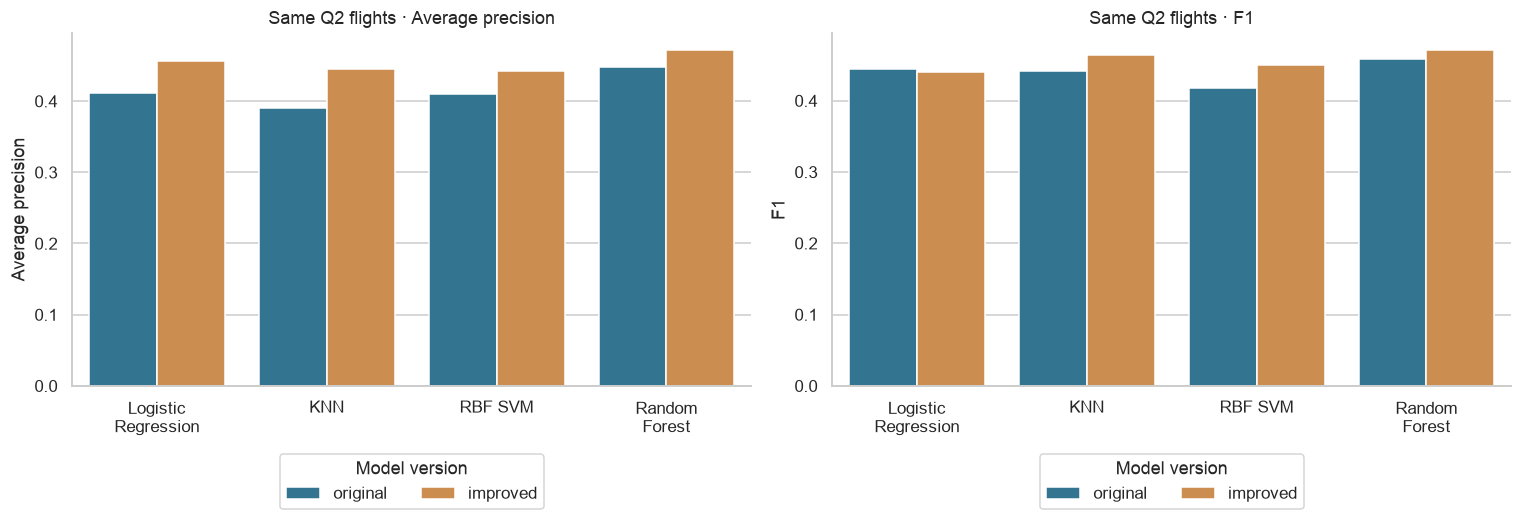

In [6]:
for name in ['always_on_time','historical_risk_ranking']:
    s=(np.zeros(len(test)) if name=='always_on_time' else test['history_airline_origin_rate']
       .fillna(test['history_origin_rate']).fillna(original['historical_baseline_fallback']).to_numpy())
    evaluations.append({'version':'baseline','model_id':name,'feature_set':'baseline','scores':s,
        'threshold':original['baseline_thresholds'][name],'score_type':'baseline_score'})
tables=make_tables(test,evaluations,CONFIG,RUN_ID,SELECTED,COHORT_SHA)
mm=tables['model_metrics.csv'];predictions=tables['flight_predictions.csv']
primary=mm.loc[mm['threshold_policy'].eq('F1')].copy()
b=primary.loc[primary['feature_set'].eq('B')].copy()
table(b[['model_version','model_id','average_precision','precision','recall','f1','accuracy','tp','fp','fn','tn']],index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for metric,ax in zip(['average_precision','f1'],axes):
    sns.barplot(data=b,x='model_id',y=metric,hue='model_version',errorbar=None,ax=ax)
    label='Average precision' if metric=='average_precision' else 'F1'
    ax.set(title='Same Q2 flights · '+label,xlabel='',ylabel=label)
    ax.set_xticks(ax.get_xticks(),['Logistic\nRegression','KNN','RBF SVM','Random\nForest'])
    ax.legend(title='Model version',loc='upper center',bbox_to_anchor=(.5,-.17),ncol=2)
plot()

## How much uncertainty is there in the apparent gain?

Flights on one day share weather and disruption. We therefore resample **whole flight dates**, with the same resampling weights for original and improved scores. The 300 paired bootstrap repetitions estimate variation across the observed Q2 dates; they do not account for all training-sample uncertainty or prove future performance.

A confidence interval crossing zero means that this test does not clearly separate the two AP values. These intervals are descriptive confirmation; they are not used to change model choices.

           model_id  ap_gain   ci_low  ci_high
logistic_regression 0.044867 0.034719 0.056681
                knn 0.054433 0.036192 0.070242
                svm 0.032351 0.018928 0.045125
      random_forest 0.023931 0.012735 0.033897


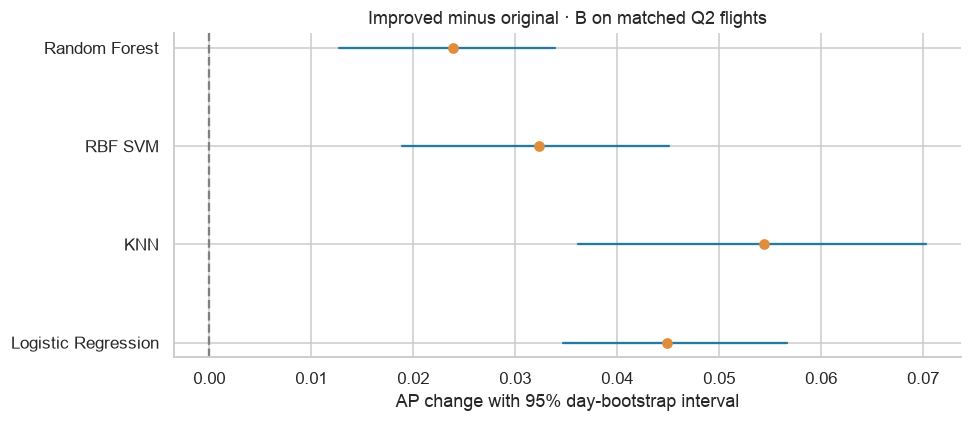

In [7]:
day_codes,days=pd.factorize(test['flight_date'],sort=True)
rng=np.random.default_rng(SEED)
weights=[np.bincount(rng.integers(0,len(days),len(days)),minlength=len(days))[day_codes]
         for _ in range(BOOTSTRAPS)]
y=test['delayed_departure'].to_numpy(dtype=int)
score_map={(e['version'],e['model_id'],e['feature_set']):e['scores'] for e in evaluations}
paired=[]
for m in NAMES:
    old=score_map[('original',m,'B')];new=score_map[('improved',m,'B')]
    differences=[average_precision_score(y,new,sample_weight=w)-average_precision_score(y,old,sample_weight=w) for w in weights]
    delta=float(average_precision_score(y,new)-average_precision_score(y,old))
    low,high=np.quantile(differences,[.025,.975])
    paired.append({'model_id':m,'ap_gain':delta,'ci_low':float(low),'ci_high':float(high)})
paired_table=pd.DataFrame(paired)
table(paired_table,index=False)
fig,ax=plt.subplots(figsize=(9,4))
for i,r in paired_table.iterrows():
    ax.plot([r.ci_low,r.ci_high],[i,i],color='#247BA0');ax.scatter(r.ap_gain,i,color='#E08D3C',zorder=3)
ax.axvline(0,color='grey',linestyle='--')
ax.set(yticks=range(4),yticklabels=[NAMES[m] for m in paired_table.model_id],
       xlabel='AP change with 95% day-bootstrap interval',title='Improved minus original · B on matched Q2 flights')
plot()

## Feature value, operating policy and ranking usefulness

A/B differences compare schedule with added information on identical flights. Feature-family tests in notebook 04 explain the staged changes within B. F1 versus F0.5 compares warning policies for unchanged scores; it cannot change AP.

The risk-prioritization view answers how many real delays appear within a fixed review budget. SVM decision scores are not probabilities and cannot be compared numerically with LR/RF probability estimates. Ranks are computed separately for each candidate.

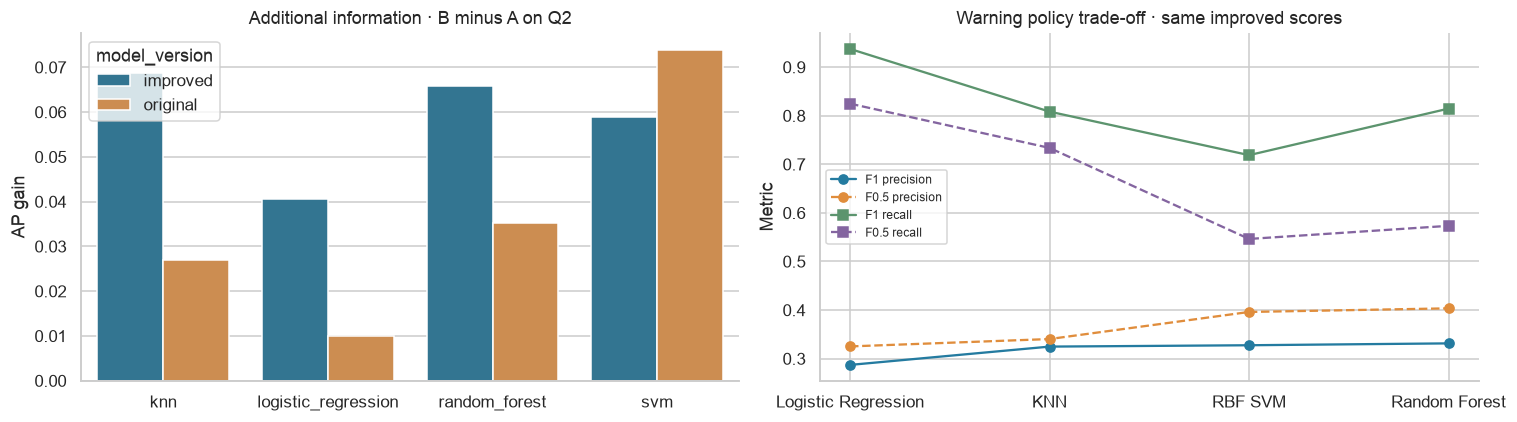

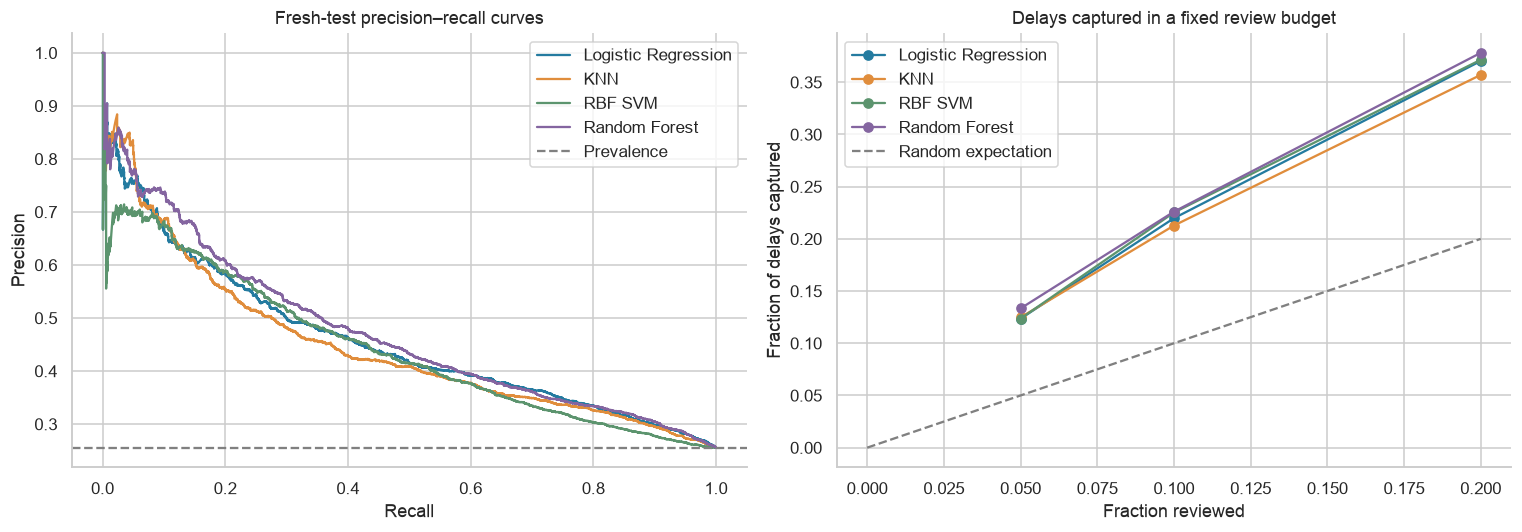

In [8]:
fc=tables['feature_comparison.csv'];priority=tables['priority_curve.csv']
fig,axes=plt.subplots(1,2,figsize=(14,4))
sns.barplot(data=fc,x='model_id',y='delta_average_precision',hue='model_version',errorbar=None,ax=axes[0])
axes[0].set(title='Additional information · B minus A on Q2',xlabel='',ylabel='AP gain')
policies=mm.loc[mm.model_version.eq('improved')&mm.feature_set.eq('B')]
for metric,marker in [('precision','o'),('recall','s')]:
    for policy,style in [('F1','-'),('F0.5','--')]:
        q=policies.loc[policies.threshold_policy.eq(policy)].set_index('model_id').reindex(NAMES)
        axes[1].plot(list(NAMES.values()),q[metric],marker=marker,linestyle=style,label=policy+' '+metric)
axes[1].set(title='Warning policy trade-off · same improved scores',ylabel='Metric');axes[1].legend(fontsize=8)
plot()
fig,axes=plt.subplots(1,2,figsize=(14,5))
pr=tables['pr_curve.csv']
for m in NAMES:
    curve=pr.loc[pr.model_version.eq('improved')&pr.model_id.eq(m)&pr.feature_set.eq('B')]
    axes[0].plot(curve['recall'],curve['precision'],label=NAMES[m])
    p=priority.loc[priority.model_version.eq('improved')&priority.model_id.eq(m)&priority.feature_set.eq('B')]
    axes[1].plot(p.capacity_fraction,p.capture_recall,marker='o',label=NAMES[m])
axes[0].axhline(y.mean(),color='grey',linestyle='--',label='Prevalence')
axes[0].set(title='Fresh-test precision–recall curves',xlabel='Recall',ylabel='Precision');axes[0].legend()
axes[1].plot([0,.2],[0,.2],color='grey',linestyle='--',label='Random expectation')
axes[1].set(title='Delays captured in a fixed review budget',xlabel='Fraction reviewed',ylabel='Fraction of delays captured');axes[1].legend()
plot()

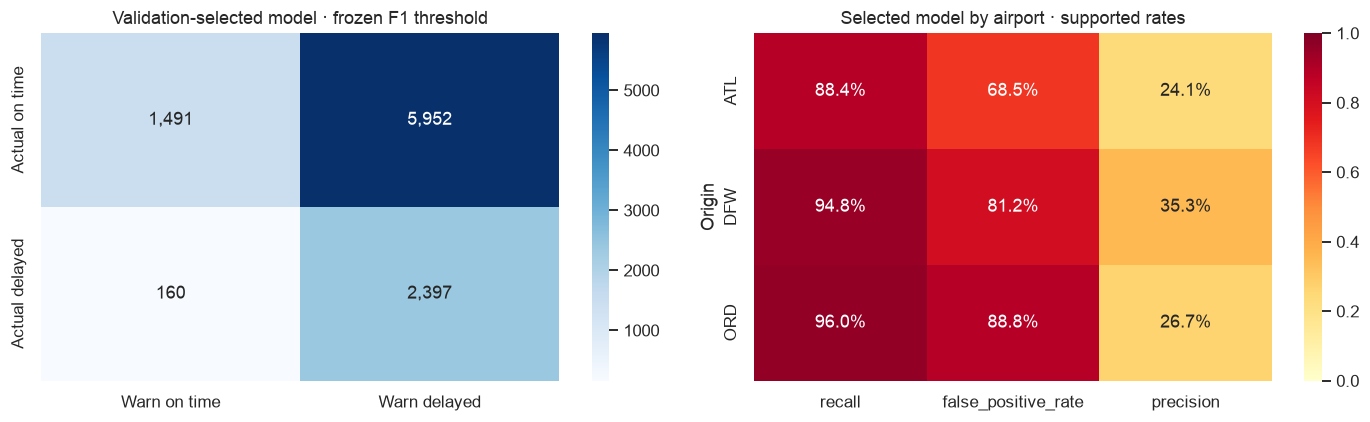

 capacity_fraction  reviewed_flights  captured_delays  false_alerts  review_precision  capture_recall  lift_over_prevalence
              0.05               500              316           184            0.6320        0.123582              2.471646
              0.10              1000              562           438            0.5620        0.219789              2.197888
              0.20              2000              947          1053            0.4735        0.370356              1.851779


In [9]:
chosen=primary.loc[primary.model_version.eq('improved')&primary.model_id.eq(SELECTED[1])&primary.feature_set.eq(SELECTED[2])].iloc[0]
cm=np.array([[chosen.tn,chosen.fp],[chosen.fn,chosen.tp]],dtype=int)
sg=tables['subgroup_metrics.csv']
airport=sg.loc[sg.model_version.eq('improved')&sg.model_id.eq(SELECTED[1])&sg.feature_set.eq(SELECTED[2])&sg.group_dimension.eq('origin')]
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.heatmap(cm,annot=True,fmt=',d',cmap='Blues',xticklabels=['Warn on time','Warn delayed'],
            yticklabels=['Actual on time','Actual delayed'],ax=axes[0])
axes[0].set_title('Validation-selected model · frozen F1 threshold')
heat=airport.set_index('group_value')[['recall','false_positive_rate','precision']]
sns.heatmap(heat,annot=True,fmt='.1%',vmin=0,vmax=1,cmap='YlOrRd',ax=axes[1])
axes[1].set(title='Selected model by airport · supported rates',ylabel='Origin')
plot()
selected_priority=priority.loc[priority.model_version.eq('improved')&priority.model_id.eq(SELECTED[1])&priority.feature_set.eq(SELECTED[2])]
table(selected_priority[['capacity_fraction','reviewed_flights','captured_delays','false_alerts','review_precision','capture_recall','lift_over_prevalence']],index=False)

## Save the new version for Tableau

Six tables go into `tableau/exports/improved/`; the six original exports remain unchanged. Filter `threshold_policy = F1` for the main model comparison, and use `model_version` to compare original versus improved on Q2. `is_validation_selected` identifies the model chosen before testing, even if another model happens to score higher here.

Use `candidate_id` plus the cohort keys when relating tables. Do not physically join prediction rows to repeated metric or curve rows and then sum duplicated counts. Unsupported subgroup rates are blank rather than zero. The F0.5 metric rows have no separate prediction table; use their recorded confusion counts for that policy.

In [10]:
# Include paired uncertainty in the metric table, avoiding an unnecessary seventh CSV.
for r in paired:
    mask=mm.model_version.eq('improved')&mm.model_id.eq(r['model_id'])&mm.feature_set.eq('B')
    for field,value in r.items():
        if field!='model_id':mm.loc[mask,'paired_'+field]=value
files={}
for name,frame in tables.items():
    path=EXPORT/name;frame.to_csv(path,index=False)
    files[name]={'rows':len(frame),'sha256':sha(path),'bytes':path.stat().st_size}
assert sha(REPORT/'selection.json')==improved['selection_sha256']
baseline_integrity=verify_baseline_files(ROOT,protected)
baseline_file_bytes_unchanged=all(sha(ROOT/p)==v for p,v in protected.items())
manifest={'run_id':RUN_ID,'test_protocol_sha256':TEST_PROTOCOL_SHA,
 'selection_sha256':improved['selection_sha256'],'selected_before_test':list(SELECTED),
 'first_outcomes_load_started_at_utc':access['first_outcomes_load_started_at_utc'],
 'selection_frozen_at_utc':selection['frozen_at_utc'],'cohort_fingerprint':COHORT_SHA,
 'test_period':['2026-04-01','2026-06-30'],'test_rows':len(test),'files':files,
 'tableau_required_filters':{'main_threshold_policy':'F1','evaluation_period':'test_q2_2026'},
 'baseline_files_unchanged':baseline_file_bytes_unchanged,'baseline_content_preserved':True,'availability_assumptions':selection['availability_note']}
save_json(EXPORT/'export_manifest.json',manifest)
results={'run_id':RUN_ID,'completed_at_utc':datetime.now(timezone.utc).isoformat(),
 'test_protocol_sha256':TEST_PROTOCOL_SHA,'test_audit':test_audit,'selected_before_test':list(SELECTED),
 'cohort_fingerprint':COHORT_SHA,'actual_delays':int(y.sum()),'paired_ap_comparison':paired,
 'metrics':json.loads(mm.to_json(orient='records')),
 'selected_priority':json.loads(selected_priority.to_json(orient='records')),
 'baseline_files_unchanged':baseline_file_bytes_unchanged,'baseline_content_preserved':True,'settings_changed_after_test':False}
save_json(REPORT/'test_results.json',results)
print('Saved six Tableau tables:',EXPORT.relative_to(ROOT))
print('Protected data/models and original preparation cells are unchanged. No settings or thresholds were adjusted after Q2 scoring.')

Saved six Tableau tables: tableau/exports/improved
All protected baseline files are unchanged. No settings or thresholds were adjusted after Q2 scoring.


## What the project can now claim

The tables above provide actual ML evidence for selecting a classifier, measuring added-information value, finding supported model failures and evaluating risk prioritization. Raw delay counts support the story but do not answer those four objectives.

Report any model that worsened, every precision/recall trade-off and the uncertainty around AP gains. Selection remains based on 2025 validation. This is still a historical simulation with unverified schedule/report/outcome availability, not a claim that all features were delivered by a live operational system.